# Análise de Vendas para Loja de E-commerce com NumPy, Pandas e Matplotlib

Mini projeto de Data Science desenvolvido durante o curso **Python para Data Science** (SENAI Suíço-Brasileira).

## Definição do Problema de Negócio

### O Problema de Negócio

Nossa loja de e-commerce está em fase de crescimento, com um volume crescente de transações diárias.

Mas muitas de nossas decisões estratégicas são baseadas em intuição e observações parciais, com os seguintes desafios:

- **Gestão de Estoque Ineficiente:** não temos clareza sobre quais produtos são nossos "campeões de venda".
- **Marketing com Baixo Retorno:** nossas campanhas de marketing são genéricas.
- **Perda de Oportunidades Sazonais:** não conseguimos identificar padrões ou tendências de vendas ao longo dos meses.
- **Expansão sem Direção:** para onde investir?

O problema central é a falta de visibilidade sobre a performance do negócio.

### Objetivos do Projeto

Este projeto de análise de dados visa transformar nossos dados brutos de vendas em insights acionáveis.

O objetivo é responder a quatro perguntas de negócio fundamentais:

1. **O que vender?**
2. **Quando agir?**
3. **Onde focar?**
4. **Para onde expandir?**

### Solução Proposta

A solução consiste em consolidar, limpar e analisar o histórico de dados de vendas da nossa plataforma.

Utilizando Python com Pandas, NumPy e Matplotlib, vamos processar essas informações e criar um relatório visual que apresente as descobertas de forma clara e intuitiva para as equipes de gestão, marketing e operações.

### Resultados Esperados e Benefícios de Negócio

- Otimização de Estoque.
- Marketing Direcionado e Eficaz.
- Planejamento Estratégico.
- Decisões Baseadas em Dados: substituiremos a intuição por dados concretos.

## Importação das Bibliotecas

In [1]:
# Importação da biblioteca para manipulação de dados em tabelas
import pandas as pd

# Importação da biblioteca NumPy para operações matemáticas e arrays
import numpy as np

# Importação da biblioteca Matplotlib para geração de gráficos
import matplotlib.pyplot as plt

# Importação da biblioteca Seaborn para visualização estatística de dados
import seaborn as sns

# Importação da biblioteca random para geração de números aleatórios
import random

# Importação das classes datetime e timedelta para manipulação de datas e intervalos de tempo
from datetime import datetime, timedelta

# Importação do módulo os para criar a pasta onde os gráficos serão salvos
import os

# Comando mágico do Jupyter Notebook que permite exibir gráficos diretamente no notebook
%matplotlib inline

In [2]:
# Versões das bibliotecas usadas (o pacote watermark pode ser instalado com: pip install watermark)
%load_ext watermark
%watermark --iversions

matplotlib: 3.11.2
numpy     : 2.5.3
pandas    : 3.0.5
seaborn   : 0.13.2



In [3]:
# Sementes fixas: garantem que os dados fictícios gerados sejam sempre os mesmos
# (assim qualquer pessoa que rodar o notebook chega aos mesmos resultados)
SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)

# Pasta onde os gráficos serão salvos
os.makedirs('imagens', exist_ok=True)

## Função Para Geração de Dados Fictícios

Exemplo de aplicação prática de muitos conceitos de Python puro e de Data Science apresentados no curso.

In [4]:
# Definição da função para gerar dados fictícios de vendas
def gera_dados_ficticios(num_registros = 600):

    """
    Gera um DataFrame do Pandas com dados de vendas fictícios.
    """

    # Mensagem inicial indicando a quantidade de registros a serem gerados
    print(f'\nIniciando a geração de {num_registros} registros de vendas...')

    # Dicionário com produtos, suas categorias e preços
    produtos = {
        'Laptop Gamer':      {'categoria': 'Eletrônicos', 'preco': 7500.00},
        'Mouse Vertical':    {'categoria': 'Eletrônicos', 'preco': 250.00},
        'Teclado Mecânico':  {'categoria': 'Acessórios',  'preco': 550.00},
        'Monitor Ultrawide': {'categoria': 'Acessórios',  'preco': 2800.00},
        'Cadeira Gamer':     {'categoria': 'Móveis',      'preco': 7500.00},
        'Headset 7.1':       {'categoria': 'Acessórios',  'preco': 800.00},
        'Placa de Vídeo':    {'categoria': 'Hardware',    'preco': 4500.00},
        'SSD 1TB':           {'categoria': 'Hardware',    'preco': 600.00}
    }

    # Cria uma lista apenas com os nomes dos produtos
    lista_produtos = list(produtos.keys())

    # Dicionário com cidades e seus respectivos estados
    cidades_estados = {
        'São Paulo': 'SP', 'Rio de Janeiro': 'RJ', 'Belo Horizonte': 'MG',
        'Porto Alegre': 'RS', 'Salvador': 'BA', 'Curitiba': 'PR', 'Fortaleza': 'CE'
    }

    # Cria uma lista apenas com os nomes das cidades
    lista_cidades = list(cidades_estados.keys())

    # Lista que armazenará os registros de vendas
    dados_vendas = []

    # Define a data inicial dos pedidos
    data_inicial = datetime(2026, 1, 1)

    # Loop para gerar os registros de vendas
    for i in range(num_registros):

        # Seleciona aleatoriamente um produto
        produto_nome = random.choice(lista_produtos)

        # Seleciona aleatoriamente uma cidade
        cidade = random.choice(lista_cidades)

        # Gera uma quantidade de produtos vendida entre 1 e 7
        quantidade = np.random.randint(1, 8)

        # Calcula a data do pedido a partir da data inicial (cerca de 5 pedidos por dia)
        data_pedido = data_inicial + timedelta(days = int(i / 5), hours = random.randint(0, 23))

        # Se o produto for Mouse ou Teclado, aplica desconto aleatório de até 10%
        if produto_nome in ['Mouse Vertical', 'Teclado Mecânico']:
            preco_unitario = produtos[produto_nome]['preco'] * np.random.uniform(0.9, 1.0)
        else:
            preco_unitario = produtos[produto_nome]['preco']

        # Adiciona um registro de venda à lista
        dados_vendas.append({
            'ID_Pedido': 1000 + i,
            'Data_Pedido': data_pedido,
            'Nome_Produto': produto_nome,
            'Categoria': produtos[produto_nome]['categoria'],
            'Preco_Unitario': round(preco_unitario, 2),
            'Quantidade': quantidade,
            'ID_Cliente': np.random.randint(100, 150),
            'Cidade': cidade,
            'Estado': cidades_estados[cidade]
        })

    # Mensagem final indicando que a geração terminou
    print('Geração de dados concluída.\n')

    # Retorna os dados no formato de DataFrame
    return pd.DataFrame(dados_vendas)

## Gerar, Carregar e Explorar os Dados

In [5]:
# Gera os dados chamando a função da célula anterior
df_vendas = gera_dados_ficticios(500)


Iniciando a geração de 500 registros de vendas...
Geração de dados concluída.



In [6]:
type(df_vendas)

pandas.DataFrame

In [7]:
# Shape (linhas, colunas)
df_vendas.shape

(500, 9)

In [8]:
# Exibe as 5 primeiras linhas do DataFrame
df_vendas.head()

,ID_Pedido,Data_Pedido,Nome_Produto,Categoria,Preco_Unitario,Quantidade,ID_Cliente,Cidade,Estado
0,1000,2026-01-01 23:00:00,Mouse Vertical,Eletrônicos,244.91,7,114,São Paulo,SP
1,1001,2026-01-01 07:00:00,Cadeira Gamer,Móveis,7500.00,3,107,Rio de Janeiro,RJ
2,1002,2026-01-01 03:00:00,Teclado Mecânico,Acessórios,527.83,5,118,Curitiba,PR
3,1003,2026-01-01 13:00:00,Mouse Vertical,Eletrônicos,226.45,7,123,Salvador,BA
4,1004,2026-01-01 02:00:00,Laptop Gamer,Eletrônicos,7500.00,5,135,São Paulo,SP


In [9]:
# Exibe as 5 últimas linhas do DataFrame
df_vendas.tail()

,ID_Pedido,Data_Pedido,Nome_Produto,Categoria,Preco_Unitario,Quantidade,ID_Cliente,Cidade,Estado
495,1495,2026-04-10 03:00:00,Cadeira Gamer,Móveis,7500.0,2,103,Belo Horizonte,MG
496,1496,2026-04-10 21:00:00,Monitor Ultrawide,Acessórios,2800.0,1,144,Rio de Janeiro,RJ
497,1497,2026-04-10 03:00:00,SSD 1TB,Hardware,600.0,2,124,Rio de Janeiro,RJ
498,1498,2026-04-10 17:00:00,Headset 7.1,Acessórios,800.0,2,139,Fortaleza,CE
499,1499,2026-04-10 08:00:00,Headset 7.1,Acessórios,800.0,7,139,São Paulo,SP


In [10]:
# Exibe informações gerais sobre o DataFrame (tipos de dados, valores não nulos)
df_vendas.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   ID_Pedido       500 non-null    int64         
 1   Data_Pedido     500 non-null    datetime64[us]
 2   Nome_Produto    500 non-null    str           
 3   Categoria       500 non-null    str           
 4   Preco_Unitario  500 non-null    float64       
 5   Quantidade      500 non-null    int64         
 6   ID_Cliente      500 non-null    int64         
 7   Cidade          500 non-null    str           
 8   Estado          500 non-null    str           
dtypes: datetime64[us](1), float64(1), int64(3), str(4)
memory usage: 35.3 KB


In [11]:
# Resumo estatístico
df_vendas.describe()

,ID_Pedido,Data_Pedido,Preco_Unitario,Quantidade,ID_Cliente
count,500.000000,500,500.000000,500.000000,500.00000
mean,1249.500000,2026-02-19 23:39:00,3114.243560,4.092000,124.20400
min,1000.000000,2026-01-01 02:00:00,225.330000,1.000000,100.00000
25%,1124.750000,2026-01-26 01:15:00,600.000000,2.000000,112.00000
50%,1249.500000,2026-02-20 04:30:00,2800.000000,4.000000,124.00000
75%,1374.250000,2026-03-16 21:30:00,7500.000000,6.000000,136.00000
max,1499.000000,2026-04-10 21:00:00,7500.000000,7.000000,149.00000
std,144.481833,NaN,2914.813049,2.001887,14.39085


In [12]:
# Tipos de dados
df_vendas.dtypes

ID_Pedido                  int64
Data_Pedido       datetime64[us]
Nome_Produto                 str
Categoria                    str
Preco_Unitario           float64
Quantidade                 int64
ID_Cliente                 int64
Cidade                       str
Estado                       str
dtype: object

## Limpeza, Pré-Processamento e Engenharia de Atributos

In [13]:
# Se a coluna 'Data_Pedido' não estiver como tipo datetime, precisamos fazer a conversão explícita
# A coluna pode ser usada para análise temporal
df_vendas['Data_Pedido'] = pd.to_datetime(df_vendas['Data_Pedido'])

In [14]:
# Engenharia de atributos
# Criando a coluna 'Faturamento' (preço x quantidade)
df_vendas['Faturamento'] = df_vendas['Preco_Unitario'] * df_vendas['Quantidade']

df_vendas.head()

,ID_Pedido,Data_Pedido,Nome_Produto,Categoria,Preco_Unitario,Quantidade,ID_Cliente,Cidade,Estado,Faturamento
0,1000,2026-01-01 23:00:00,Mouse Vertical,Eletrônicos,244.91,7,114,São Paulo,SP,1714.37
1,1001,2026-01-01 07:00:00,Cadeira Gamer,Móveis,7500.00,3,107,Rio de Janeiro,RJ,22500.00
2,1002,2026-01-01 03:00:00,Teclado Mecânico,Acessórios,527.83,5,118,Curitiba,PR,2639.15
3,1003,2026-01-01 13:00:00,Mouse Vertical,Eletrônicos,226.45,7,123,Salvador,BA,1585.15
4,1004,2026-01-01 02:00:00,Laptop Gamer,Eletrônicos,7500.00,5,135,São Paulo,SP,37500.00


In [15]:
# Engenharia de atributos
# Usando uma função lambda para criar uma coluna de status de entrega
df_vendas['Status_Entrega'] = df_vendas['Estado'].apply(lambda estado: 'Rápida' if estado in ['SP', 'RJ', 'MG'] else 'Normal')

In [16]:
# Exibe informações gerais sobre o DataFrame (tipos de dados, valores não nulos)
df_vendas.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   ID_Pedido       500 non-null    int64         
 1   Data_Pedido     500 non-null    datetime64[us]
 2   Nome_Produto    500 non-null    str           
 3   Categoria       500 non-null    str           
 4   Preco_Unitario  500 non-null    float64       
 5   Quantidade      500 non-null    int64         
 6   ID_Cliente      500 non-null    int64         
 7   Cidade          500 non-null    str           
 8   Estado          500 non-null    str           
 9   Faturamento     500 non-null    float64       
 10  Status_Entrega  500 non-null    str           
dtypes: datetime64[us](1), float64(2), int64(3), str(5)
memory usage: 43.1 KB


In [17]:
# Exibe as 5 primeiras linhas novamente para ver as novas colunas
df_vendas.head()

,ID_Pedido,Data_Pedido,Nome_Produto,Categoria,Preco_Unitario,Quantidade,ID_Cliente,Cidade,Estado,Faturamento,Status_Entrega
0,1000,2026-01-01 23:00:00,Mouse Vertical,Eletrônicos,244.91,7,114,São Paulo,SP,1714.37,Rápida
1,1001,2026-01-01 07:00:00,Cadeira Gamer,Móveis,7500.00,3,107,Rio de Janeiro,RJ,22500.00,Rápida
2,1002,2026-01-01 03:00:00,Teclado Mecânico,Acessórios,527.83,5,118,Curitiba,PR,2639.15,Normal
3,1003,2026-01-01 13:00:00,Mouse Vertical,Eletrônicos,226.45,7,123,Salvador,BA,1585.15,Normal
4,1004,2026-01-01 02:00:00,Laptop Gamer,Eletrônicos,7500.00,5,135,São Paulo,SP,37500.00,Rápida


## Análise 1 - Top 10 Produtos Mais Vendidos

**Quais os top 10 produtos mais vendidos?**

> Como o catálogo tem 8 produtos, o ranking mostra todos eles.

In [18]:
# Agrupa por nome do produto, soma a quantidade e ordena para encontrar os mais vendidos
top_10_produtos = df_vendas.groupby('Nome_Produto')['Quantidade'].sum().sort_values(ascending = False).head(10)

In [19]:
# Exibe o resultado
top_10_produtos

Nome_Produto
Cadeira Gamer        296
Monitor Ultrawide    296
Headset 7.1          271
SSD 1TB              264
Mouse Vertical       245
Teclado Mecânico     242
Placa de Vídeo       241
Laptop Gamer         191
Name: Quantidade, dtype: int64

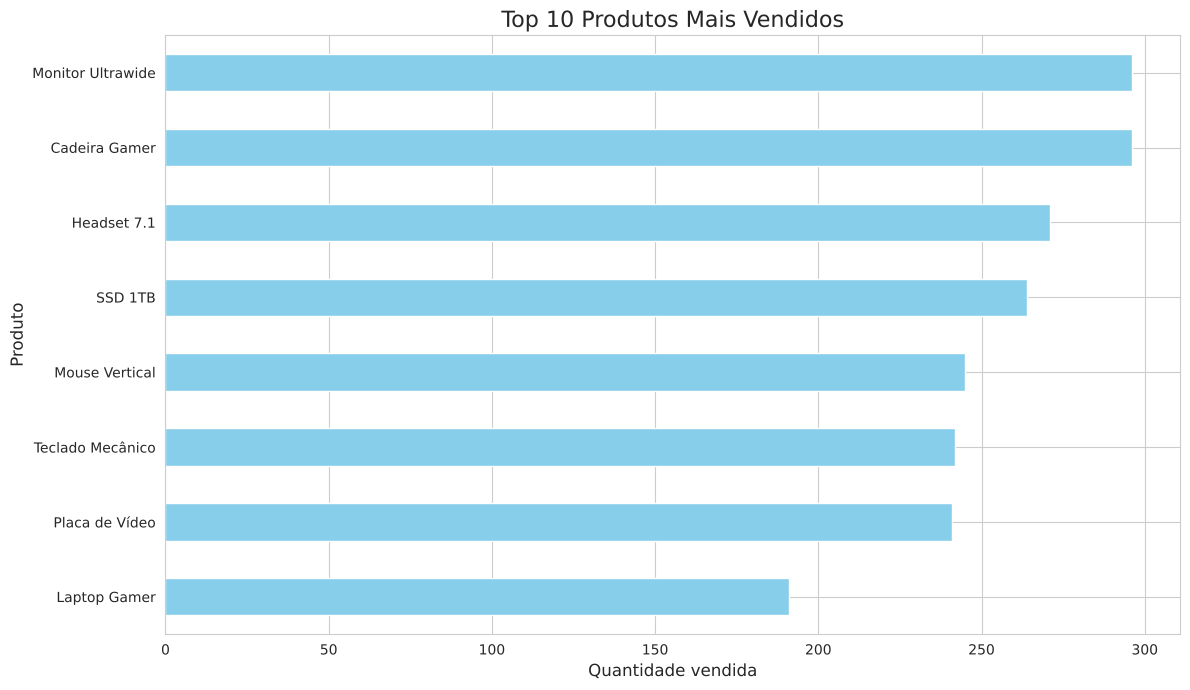

In [20]:
# Define um estilo para os gráficos
sns.set_style('whitegrid')

# Cria a figura e os eixos
plt.figure(figsize = (12, 7))

# Cria o gráfico de barras horizontais
top_10_produtos.sort_values(ascending = True).plot(kind = 'barh', color = 'skyblue')

# Adiciona títulos e labels
plt.title('Top 10 Produtos Mais Vendidos', fontsize = 16)
plt.xlabel('Quantidade vendida', fontsize = 12)
plt.ylabel('Produto', fontsize = 12)

# Ajusta, salva e exibe o gráfico
plt.tight_layout()
plt.savefig('imagens/01_top_produtos.png', dpi = 100)
plt.show()

## Análise 2 - Faturamento Mensal

**Qual foi o faturamento mensal?**

In [21]:
df_vendas.tail(100)

,ID_Pedido,Data_Pedido,Nome_Produto,Categoria,Preco_Unitario,Quantidade,ID_Cliente,Cidade,Estado,Faturamento,Status_Entrega
400,1400,2026-03-22 14:00:00,Teclado Mecânico,Acessórios,548.52,5,118,São Paulo,SP,2742.6,Rápida
401,1401,2026-03-22 09:00:00,Headset 7.1,Acessórios,800.00,5,104,Salvador,BA,4000.0,Normal
402,1402,2026-03-22 08:00:00,Placa de Vídeo,Hardware,4500.00,2,127,Curitiba,PR,9000.0,Normal
403,1403,2026-03-22 09:00:00,SSD 1TB,Hardware,600.00,2,121,Fortaleza,CE,1200.0,Normal
404,1404,2026-03-22 15:00:00,Monitor Ultrawide,Acessórios,2800.00,5,105,Porto Alegre,RS,14000.0,Normal
...,...,...,...,...,...,...,...,...,...,...,...
495,1495,2026-04-10 03:00:00,Cadeira Gamer,Móveis,7500.00,2,103,Belo Horizonte,MG,15000.0,Rápida
496,1496,2026-04-10 21:00:00,Monitor Ultrawide,Acessórios,2800.00,1,144,Rio de Janeiro,RJ,2800.0,Rápida
497,1497,2026-04-10 03:00:00,SSD 1TB,Hardware,600.00,2,124,Rio de Janeiro,RJ,1200.0,Rápida
498,1498,2026-04-10 17:00:00,Headset 7.1,Acessórios,800.00,2,139,Fortaleza,CE,1600.0,Normal


In [22]:
# Cria uma coluna 'Mes' para facilitar o agrupamento mensal
df_vendas['Mes'] = df_vendas['Data_Pedido'].dt.to_period('M')

In [23]:
df_vendas.head()

,ID_Pedido,Data_Pedido,Nome_Produto,Categoria,Preco_Unitario,Quantidade,ID_Cliente,Cidade,Estado,Faturamento,Status_Entrega,Mes
0,1000,2026-01-01 23:00:00,Mouse Vertical,Eletrônicos,244.91,7,114,São Paulo,SP,1714.37,Rápida,2026-01
1,1001,2026-01-01 07:00:00,Cadeira Gamer,Móveis,7500.00,3,107,Rio de Janeiro,RJ,22500.00,Rápida,2026-01
2,1002,2026-01-01 03:00:00,Teclado Mecânico,Acessórios,527.83,5,118,Curitiba,PR,2639.15,Normal,2026-01
3,1003,2026-01-01 13:00:00,Mouse Vertical,Eletrônicos,226.45,7,123,Salvador,BA,1585.15,Normal,2026-01
4,1004,2026-01-01 02:00:00,Laptop Gamer,Eletrônicos,7500.00,5,135,São Paulo,SP,37500.00,Rápida,2026-01


In [24]:
# Agrupa por mês e soma o faturamento
faturamento_mensal = df_vendas.groupby('Mes')['Faturamento'].sum()

In [25]:
# Converte o índice para string para facilitar a plotagem no gráfico
faturamento_mensal.index = faturamento_mensal.index.strftime('%Y-%m')

In [26]:
# Formata para duas casas decimais
faturamento_mensal.map('R$ {:,.2f}'.format)

Mes
2026-01    R$ 1,848,447.14
2026-02    R$ 1,798,725.26
2026-03    R$ 1,876,518.01
2026-04      R$ 602,326.31
Name: Faturamento, dtype: str

> **Atenção:** com 500 pedidos (cerca de 5 por dia), os dados vão de janeiro até o início de abril de 2026. Abril é um **mês incompleto**, por isso o faturamento dele aparece bem menor no gráfico.

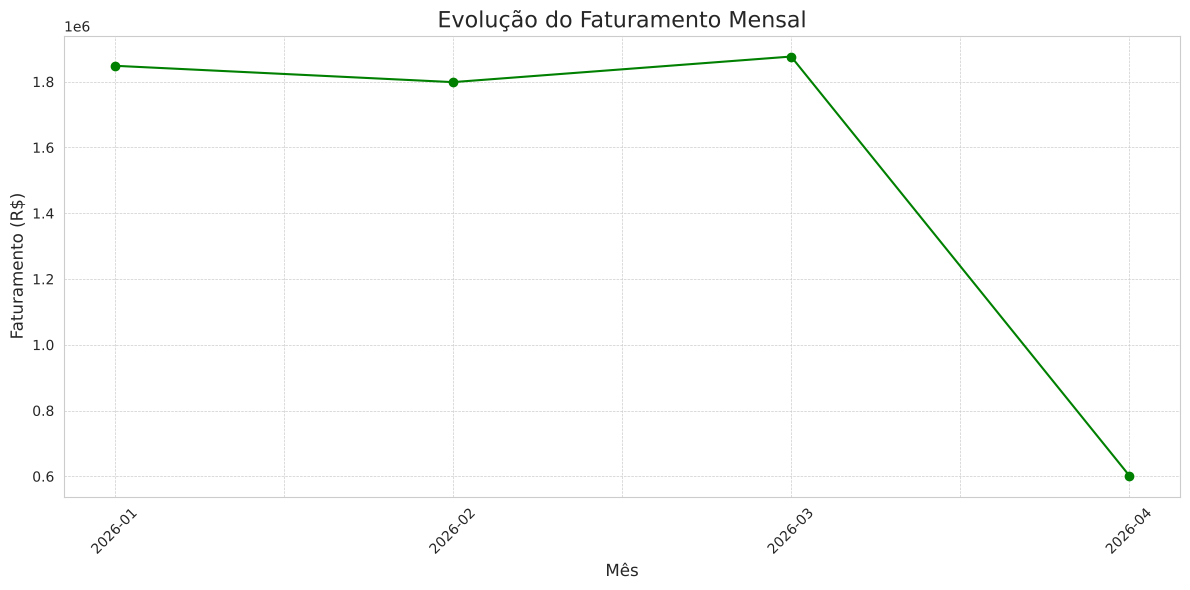

In [27]:
# Cria uma nova figura com tamanho de 12 por 6 polegadas
plt.figure(figsize = (12, 6))

# Plota os dados de faturamento mensal em formato de linha
faturamento_mensal.plot(kind = 'line', marker = 'o', linestyle = '-', color = 'green')

# Define o título do gráfico com fonte de tamanho 16
plt.title('Evolução do Faturamento Mensal', fontsize = 16)

# Define o rótulo do eixo X
plt.xlabel('Mês', fontsize = 12)

# Define o rótulo do eixo Y
plt.ylabel('Faturamento (R$)', fontsize = 12)

# Rotaciona os valores do eixo X em 45 graus para melhor visualização
plt.xticks(rotation = 45)

# Adiciona uma grade com estilo tracejado e linhas finas
plt.grid(True, which = 'both', linestyle = '--', linewidth = 0.5)

# Ajusta automaticamente os elementos para evitar sobreposição, salva e exibe o gráfico
plt.tight_layout()
plt.savefig('imagens/02_faturamento_mensal.png', dpi = 100)
plt.show()

## Análise 3 - Vendas Por Estado

**Qual o total de vendas por estado?**

In [28]:
# Agrupa por estado e soma o faturamento
vendas_estados = df_vendas.groupby('Estado')['Faturamento'].sum().sort_values(ascending = False)

In [29]:
# Formata para duas casas decimais
vendas_estados.map('R$ {:,.2f}'.format)

Estado
CE    R$ 1,007,450.05
BA      R$ 966,172.77
RS      R$ 915,637.00
PR      R$ 894,151.31
MG      R$ 805,778.64
RJ      R$ 796,433.79
SP      R$ 740,393.16
Name: Faturamento, dtype: str

Paletas de cores do Seaborn: https://seaborn.pydata.org/generated/seaborn.color_palette.html

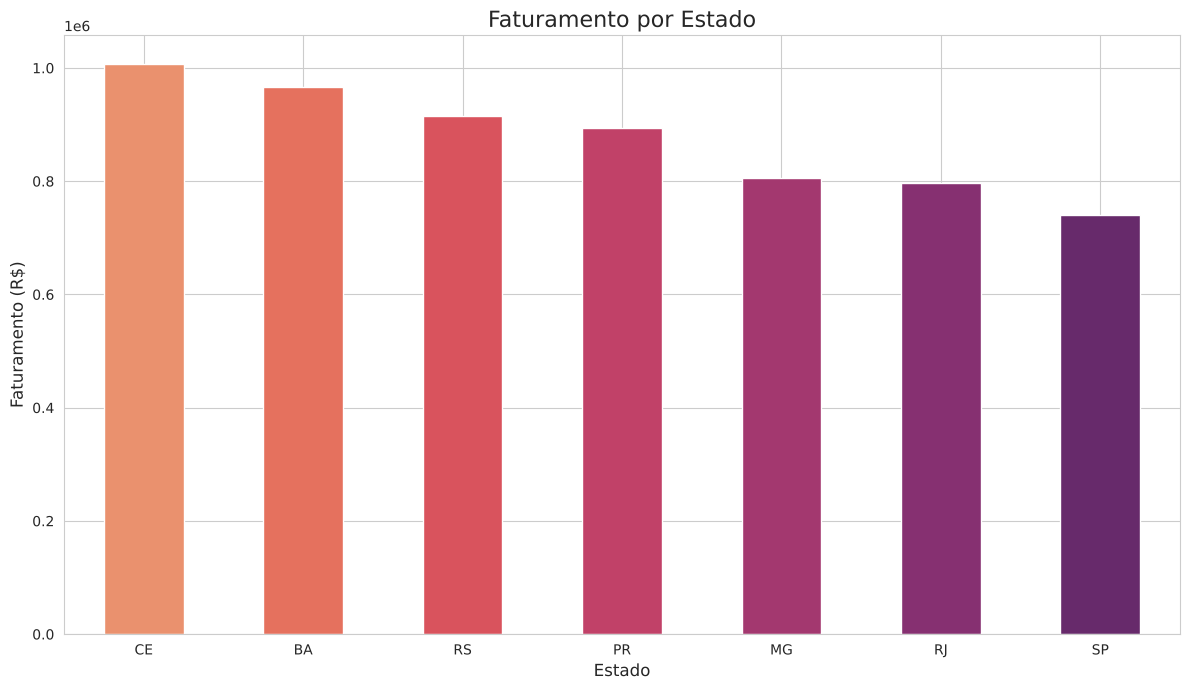

In [30]:
# Cria uma nova figura com tamanho de 12 por 7 polegadas
plt.figure(figsize = (12, 7))

# Plota os dados de faturamento por estado em formato de gráfico de barras
# Usando a paleta de cores "flare" do Seaborn
vendas_estados.plot(kind = 'bar', color = sns.color_palette('flare', len(vendas_estados)))

# Define o título do gráfico com fonte de tamanho 16
plt.title('Faturamento por Estado', fontsize = 16)

# Define o rótulo do eixo X
plt.xlabel('Estado', fontsize = 12)

# Define o rótulo do eixo Y
plt.ylabel('Faturamento (R$)', fontsize = 12)

# Mantém os rótulos do eixo X na horizontal (sem rotação)
plt.xticks(rotation = 0)

# Ajusta automaticamente os elementos do gráfico para evitar sobreposição, salva e exibe
plt.tight_layout()
plt.savefig('imagens/03_faturamento_estado.png', dpi = 100)
plt.show()

## Análise 4 - Faturamento Por Categoria

**Qual o faturamento total por categoria?**

In [31]:
# Agrupa por categoria e soma o faturamento
faturamento_categoria = df_vendas.groupby('Categoria')['Faturamento'].sum().sort_values(ascending = False)
faturamento_categoria

Categoria
Móveis         2220000.00
Eletrônicos    1491162.40
Hardware       1242900.00
Acessórios     1171954.32
Name: Faturamento, dtype: float64

In [32]:
# O .map('{:,.2f}'.format) é opcional, mas deixa a visualização do número mais clara
faturamento_categoria.map('R$ {:,.2f}'.format)

Categoria
Móveis         R$ 2,220,000.00
Eletrônicos    R$ 1,491,162.40
Hardware       R$ 1,242,900.00
Acessórios     R$ 1,171,954.32
Name: Faturamento, dtype: str

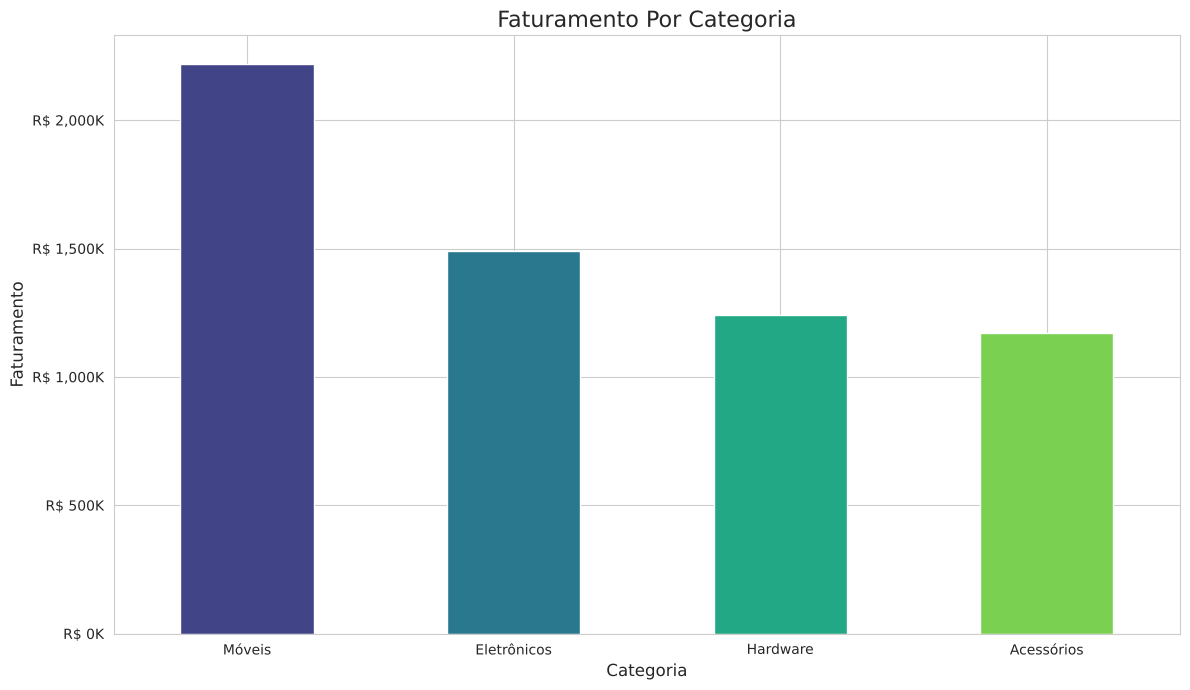

In [33]:
# Importa a função FuncFormatter para formatar os eixos
from matplotlib.ticker import FuncFormatter

# Ordena os dados para o gráfico ficar mais fácil de ler
faturamento_ordenado = faturamento_categoria.sort_values(ascending = False)

# Cria a Figura e os Eixos (ax) com plt.subplots()
# Isso nos dá mais controle sobre os elementos do gráfico.
fig, ax = plt.subplots(figsize = (12, 7))

# Cria uma função para formatar os números
# Esta função recebe um valor 'y' e o transforma em uma string no formato 'R$ XXK'
def formatador_milhares(y, pos):
    """Formata o valor em milhares (K) com cifrão R$."""
    return f'R$ {y/1000:,.0f}K'

# Cria o objeto formatador
formatter = FuncFormatter(formatador_milhares)

# Aplica o formatador ao eixo Y (ax.yaxis)
ax.yaxis.set_major_formatter(formatter)

# Plota os dados usando o objeto 'ax'
faturamento_ordenado.plot(kind = 'bar', ax = ax, color = sns.color_palette('viridis', len(faturamento_ordenado)))

# Adiciona títulos e labels usando 'ax.set_...'
ax.set_title('Faturamento Por Categoria', fontsize = 16)
ax.set_xlabel('Categoria', fontsize = 12)
ax.set_ylabel('Faturamento', fontsize = 12)

# Ajusta a rotação dos rótulos do eixo X
plt.xticks(rotation = 0, ha = 'center')

# Garante que tudo fique bem ajustado na imagem final, salva e exibe
plt.tight_layout()
plt.savefig('imagens/04_faturamento_categoria.png', dpi = 100)
plt.show()

## Conclusão

> Os números abaixo valem para os dados fictícios gerados com a semente 42 (500 pedidos, de janeiro ao início de abril de 2026). Faturamento total: **R$ 6,13 milhões**.

**1. O que vender?** A **Cadeira Gamer** e o **Monitor Ultrawide** foram os mais vendidos (296 unidades cada). Sozinha, a Cadeira Gamer fez da categoria **Móveis** a maior em faturamento (R$ 2,22 milhões, cerca de 36% do total). O Laptop Gamer vendeu menos unidades (191), mas, pelo preço alto, também pesa no faturamento. Esses itens precisam de estoque garantido.

**2. Quando agir?** O faturamento ficou estável, entre R$ 1,80 e R$ 1,88 milhão por mês de janeiro a março, com março um pouco acima. A queda de abril não é real: o mês só tem os primeiros dias de dados. Para identificar sazonalidade de verdade, é preciso um histórico maior (12 meses ou mais).

**3. Onde focar?** **CE** (R$ 1,01 milhão) e **BA** (R$ 0,97 milhão) lideraram o faturamento. **SP** ficou em último (R$ 0,74 milhão), mesmo sendo um estado de entrega rápida. Isso indica espaço para campanhas de marketing direcionadas em SP, RJ e MG.

**4. Para onde expandir?** Nordeste e Sul (CE, BA, RS e PR) mostraram a demanda mais forte. São candidatos a ganhar centro de distribuição ou prazo de entrega menor, já que hoje recebem entrega "Normal".

### Próximos passos

- Aplicar a mesma análise com dados reais de vendas.
- Analisar o comportamento dos clientes (recorrência e ticket médio por `ID_Cliente`).
- Levar os resultados para um dashboard interativo (Power BI, Streamlit, etc.).